**Aim:** Identify subgroups of __Astrocytes__ and __Microglia__

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)

In [1]:
import scez

Global seed set to 0


scanpy==1.9.1 anndata==0.8.0 umap==0.5.3 numpy==1.22.4 scipy==1.9.0 pandas==1.4.3 scikit-learn==1.1.2 statsmodels==0.13.2 python-igraph==0.9.11 pynndescent==0.5.7


In [4]:
from utils import *

In [5]:
from upsetplot import from_contents, UpSet

In [6]:
def add_marker_feature(adata,marker,marker_name,clusters_name,thr = 0,figsize=(10,4)):

    df = pd.concat([
        adata.obs.groupby([marker_name,clusters_name]).size()[f'{marker}+'],
        adata.obs.groupby([marker_name,clusters_name]).size()[f'{marker}-']
    ],axis=1).rename(columns={0:f'{marker}+',1:f'{marker}-'})
    
    # Make some labels.
    labels = df[f'{marker}+'] / df.sum(axis=1) * 100
    labels = labels.round(decimals=1)
    labels.sort_values(ascending=False,inplace=True)
    df = df.loc[labels.index,]
    
    ax = df.plot.bar(stacked=True,rot=0,figsize=figsize)

    rects = ax.patches

    for rect, label in zip(rects, labels):
        height = rect.get_height()
        ax.text(
            rect.get_x() + rect.get_width() / 2, height + 5, str(label) + "%", 
            ha="center", va="bottom", fontsize=8
        )

    ax.set_yscale('log')
    ax.set_ylabel('# of cells')
    return ax


In [49]:
def revert_upset_dataframe(up_data):
    return up_data.reset_index().set_index('id')

def get_intersection(up_data,which='all'):
    df = revert_upset_dataframe(up_data)
    if which == 'all':
        df = df[df.sum(axis=1) == 1]
        l = list()
        for col in df.columns:
            l.append((col, df.index[df[col]].tolist()))
            
        out = pd.DataFrame(l,columns=['cluster_vs_all','unique_ranked_genes'])
        out.unique_ranked_genes = out.unique_ranked_genes.str.join(',')
            
    else:
        out = pd.DataFrame(
        {
            'cluster_vs_all':which,
            'unique_ranked_genes':[','.join(df.index[df[which.split(',')].sum(axis=1)==2])]
        }
    )

    return out

## Load data 

In [7]:
results_file = 'celltyping/adata_non_neuron-clustered-labeled.h5ad.gz'

adata_non_neuron = sc.read_h5ad(results_file)

## Astrocytes

In [13]:
adata_Astrocytes = adata_non_neuron[adata_non_neuron.obs.label == 'Astrocytes'].copy()

In [21]:
adata_Astrocytes

AnnData object with n_obs × n_vars = 1000 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Apod label', 'TdT label', 'Sox11 label', 'label', 'leiden_non_neuron'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'dendrogram_label', 'dendrogram_leiden_non_neuron', 'hvg', 'label_colors', 'leiden', 'neighbors', 'pca', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    varm: 'PCs'
    layers: 'counts', 'scaled', 'scvi_normalized'
    obsp: 'connectivities', 'distances'

#### Scale

In [22]:
adata_Astrocytes.layers['scaled'] = sc.pp.scale(adata_Astrocytes, copy=True).X

In [23]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_Astrocytes, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

In [24]:
sc.tl.pca(adata_Astrocytes)

In [36]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata_Astrocytes, use_rep="X_scVI")
sc.tl.umap(adata_Astrocytes, min_dist=0.5)

In [37]:
# neighbors were already computed using scVI
sc.tl.leiden(adata_Astrocytes, key_added="leiden_Astrocytes", resolution=0.1)

In [38]:
sc.tl.dendrogram(adata_Astrocytes,'leiden_Astrocytes') 

In [39]:
# ax = sc.pl.dotplot(
#     adata_Astrocytes,
#     'Snap25',# not_neuron_genes, 
#     groupby=['leiden_Astrocytes'], #,'leiden_scVI'
#     swap_axes=False, dendrogram=True,
#     colorbar_title='mean z-score', 
#     layer='scaled', 
#     vmin=-1, vmax=1, cmap='RdBu_r',
#     # save = 'non_neuron'
# )

# # !mv -v figures/dotplot_non_neuron.pdf celltyping/non_neuron_dotplot.pdf

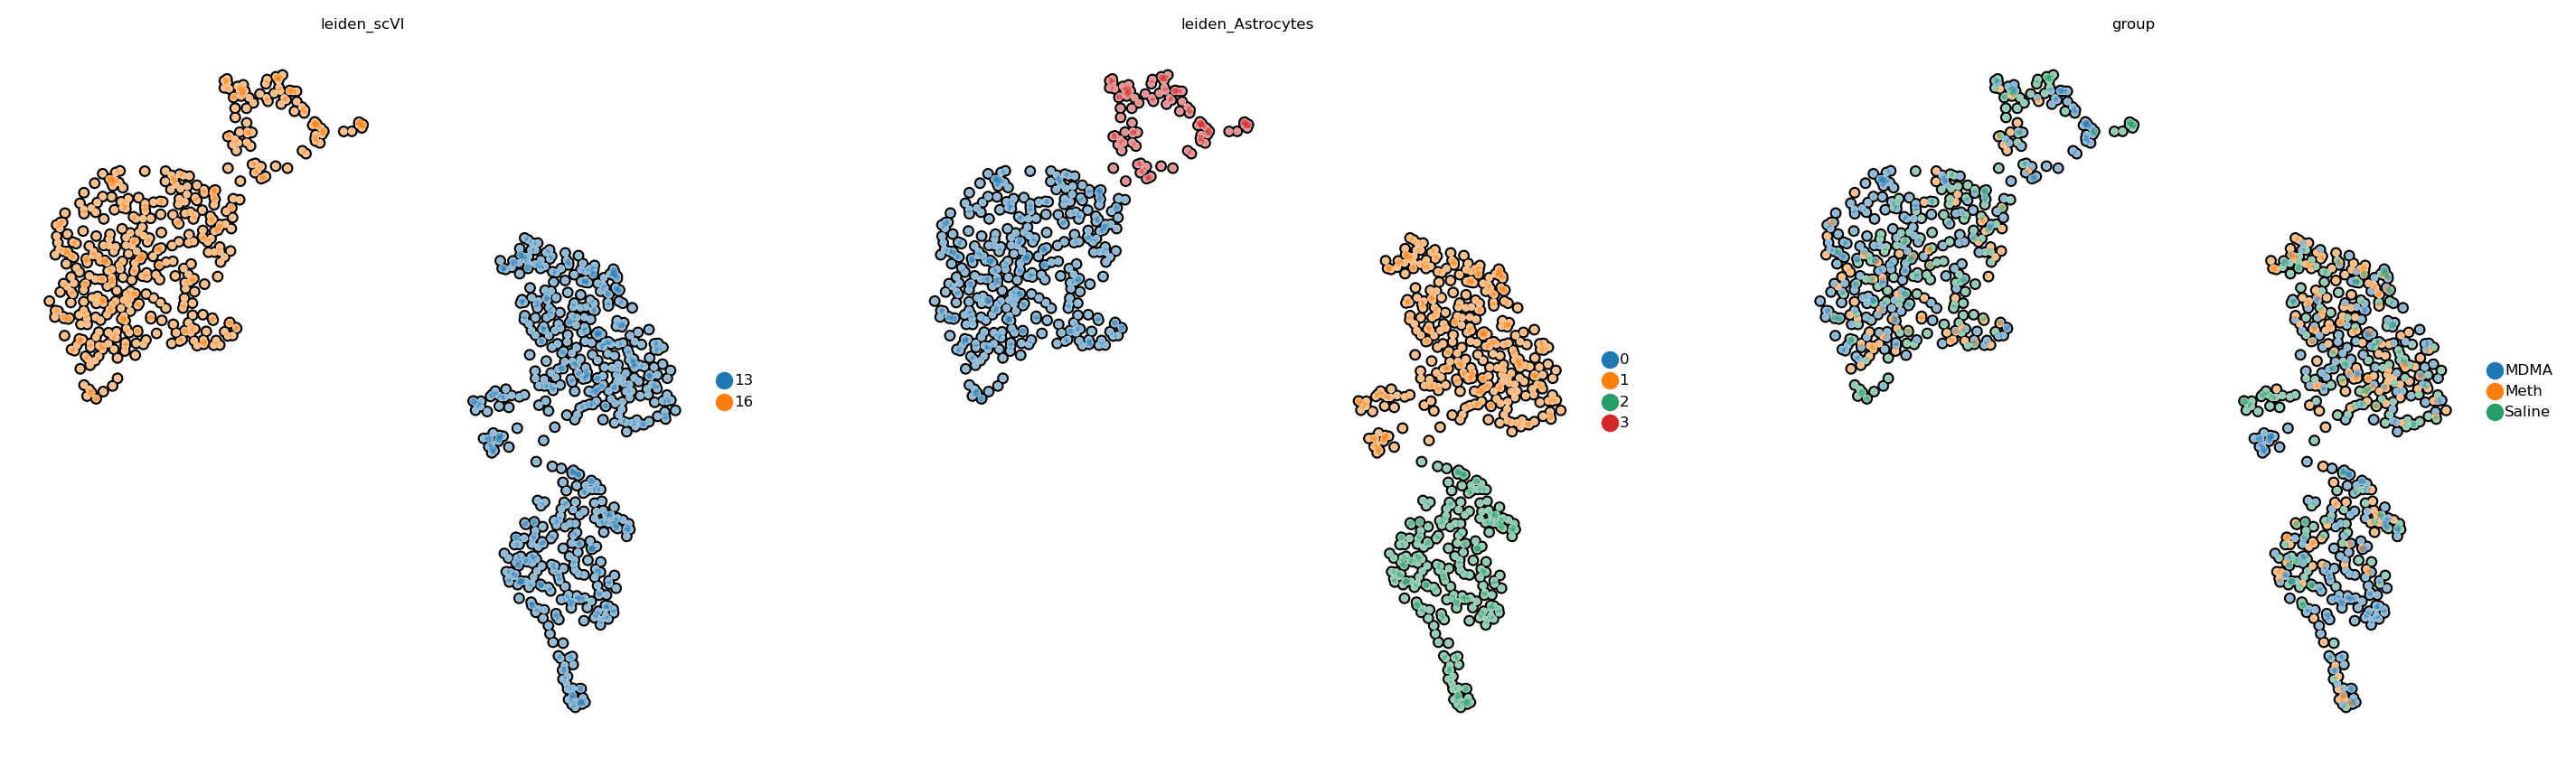

‘figures/umap_Astrocytes.pdf’ -> ‘celltyping/Astrocytes_umap.pdf’


In [76]:
sc.pl.umap(
    adata_Astrocytes,
    color=[
        'leiden_scVI',
        'leiden_Astrocytes',
        # "Mog","Ptprb",
        # "Snap25",'Sox11',
        # "Apod",
        'group',
    ],
    vmax=2,
    vmin=0,
    layer='scaled', 
    color_map="Reds",
    frameon=False,alpha=0.5,size=30,
    # legend_loc='on data',
    add_outline=0.1,
    save = '_Astrocytes'
)

!mv -v figures/umap_Astrocytes.pdf celltyping/Astrocytes_umap.pdf

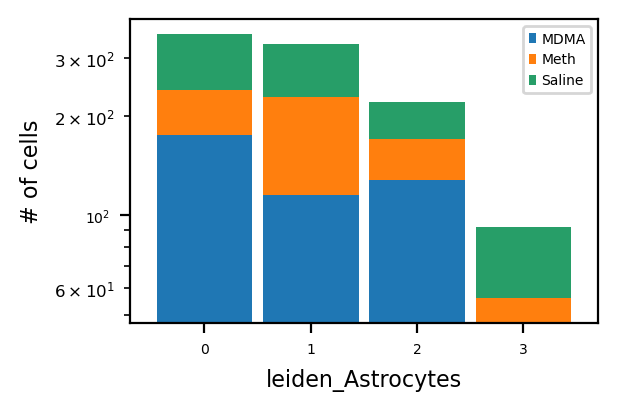

In [42]:
df = pd.DataFrame(adata_Astrocytes.obs.groupby(['group','leiden_Astrocytes']).size()).reset_index().pivot(
    index='group', columns='leiden_Astrocytes', values=0
).T

ax = df.plot.bar(stacked=True,rot=0,figsize=(3,2),width=0.9,fontsize=5)

ax.patch.set_facecolor('white')
ax.set_ylabel('# of cells',fontsize=8)
ax.set_xlabel('leiden_Astrocytes',fontsize=8)
ax.grid(False)
ax.set_yscale('log')

plt.legend(loc='upper right', 
           # bbox_to_anchor=(1.2, 0.5),
           fontsize=5)
plt.show()

### rank genes

In [54]:
sc.tl.rank_genes_groups(
    adata_Astrocytes, 'leiden_Astrocytes', method='t-test'
)

In [57]:
top_ranked_Astrocytes_clusters_full = rank_genes_to_df(
    adata_Astrocytes, n = 50
)

# top_ranked_neuron_clusters = top_ranked_neuron_clusters_full.filter(regex='names')

In [73]:
# Create a Pandas Excel writer using XlsxWriter as the engine.
writer = pd.ExcelWriter('celltyping/top_ranked_Astrocytes_clusters_full.xlsx', engine='xlsxwriter')

# Write each dataframe to a different worksheet.
top_ranked_Astrocytes_clusters_full.to_excel(writer, sheet_name='full')

# Close the Pandas Excel writer and output the Excel file.
writer.save()

## Microglia

In [19]:
adata_Microglia = adata_non_neuron[adata_non_neuron.obs.label == 'Microglia']

In [59]:
adata_Microglia

View of AnnData object with n_obs × n_vars = 1840 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Apod label', 'TdT label', 'Sox11 label', 'label', 'leiden_non_neuron'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'dendrogram_label', 'dendrogram_leiden_non_neuron', 'hvg', 'label_colors', 'leiden', 'neighbors', 'pca', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    varm: 'PCs'
    layers: 'counts', 'scaled', 'scvi_normalized'
    obsp: 'connectivities', 'distances'

#### Scale

In [60]:
adata_Microglia.layers['scaled'] = sc.pp.scale(adata_Microglia, copy=True).X

In [61]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_Microglia, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

In [62]:
sc.tl.pca(adata_Microglia)

In [63]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata_Microglia, use_rep="X_scVI")
sc.tl.umap(adata_Microglia, min_dist=0.5)

In [64]:
# neighbors were already computed using scVI
sc.tl.leiden(adata_Microglia, key_added="leiden_Microglia", resolution=0.1)

In [65]:
sc.tl.dendrogram(adata_Microglia,'leiden_Microglia') 

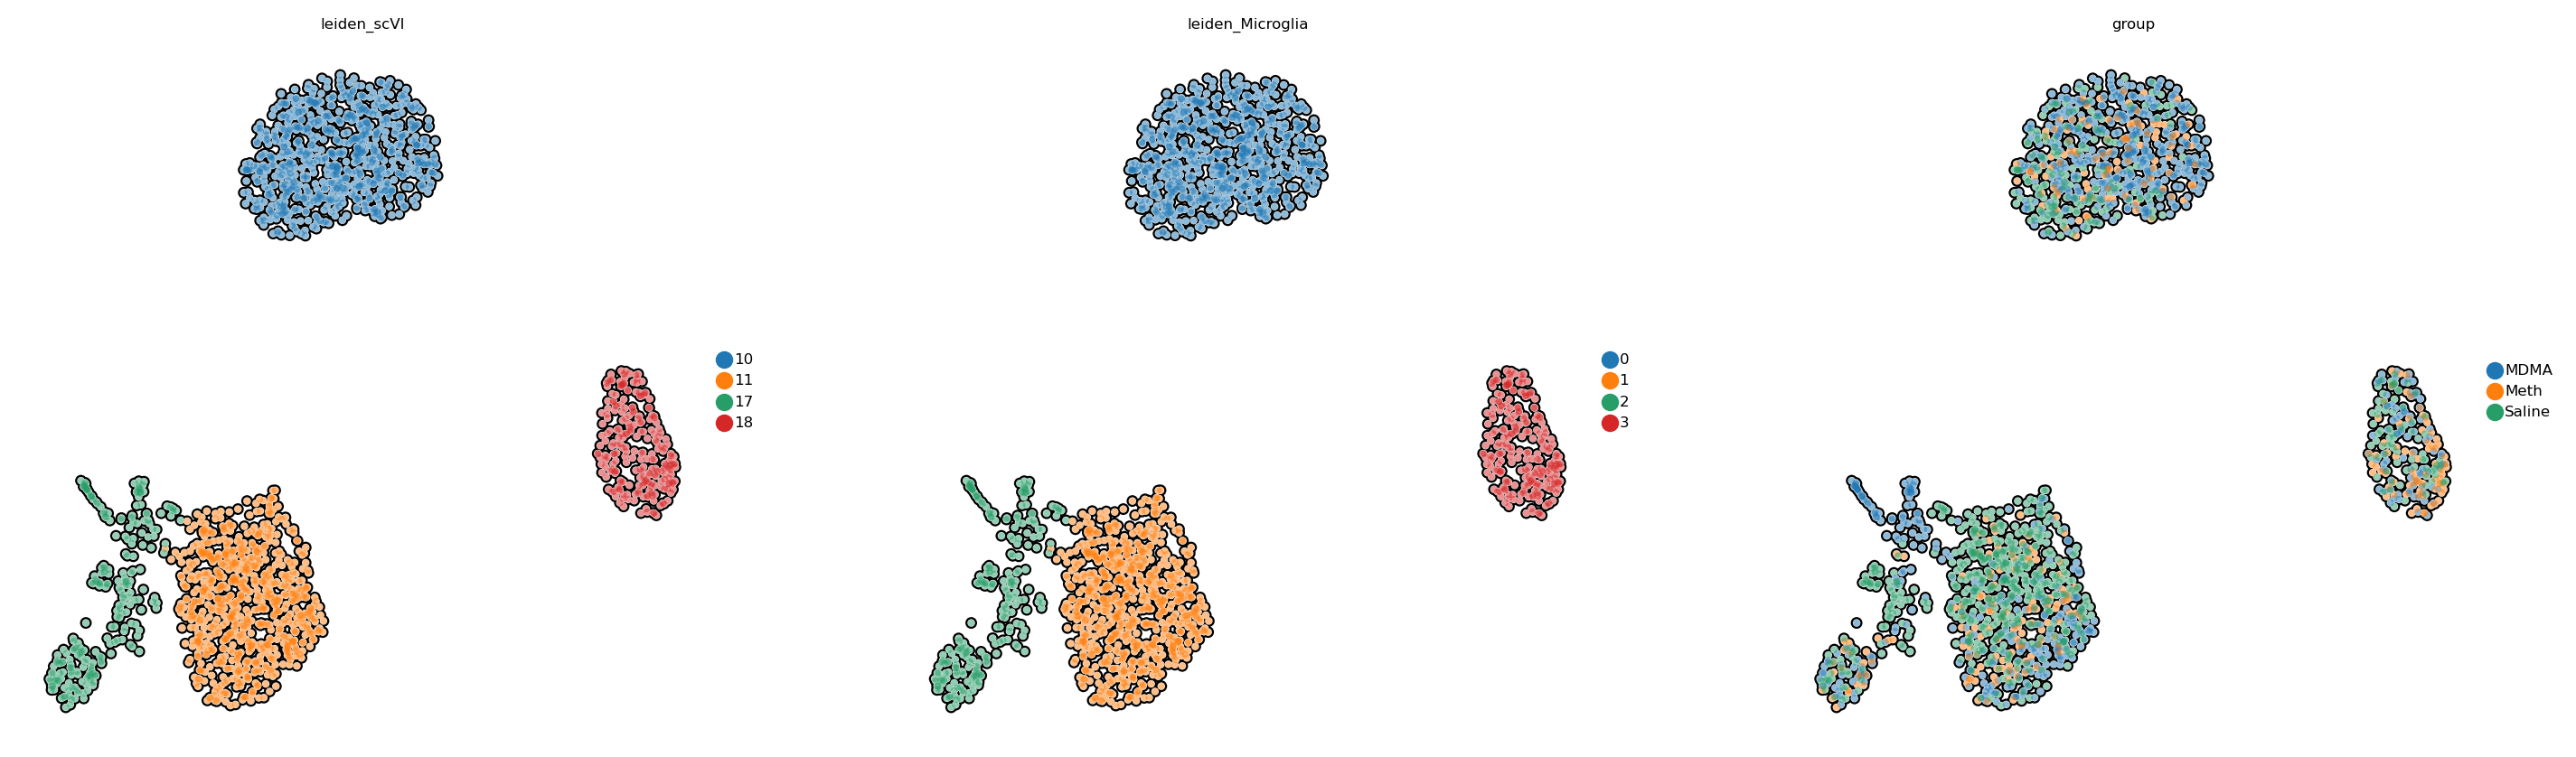

‘figures/umap_Microglia.pdf’ -> ‘celltyping/Microglia_umap.pdf’


In [75]:
sc.pl.umap(
    adata_Microglia,
    color=[
        'leiden_scVI',
        'leiden_Microglia',
        # "Mog","Ptprb",
        # "Snap25",'Sox11',
        # "Apod",
        'group',
    ],
    vmax=2,
    vmin=0,
    layer='scaled', 
    color_map="Reds",
    frameon=False,alpha=0.5,size=30,
    # legend_loc='on data',
    add_outline=0.1,
    save = '_Microglia'
)

!mv -v figures/umap_Microglia.pdf celltyping/Microglia_umap.pdf

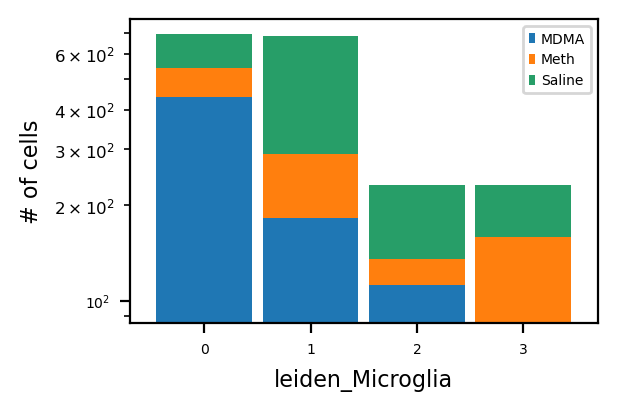

In [68]:
df = pd.DataFrame(adata_Microglia.obs.groupby(['group','leiden_Microglia']).size()).reset_index().pivot(
    index='group', columns='leiden_Microglia', values=0
).T

ax = df.plot.bar(stacked=True,rot=0,figsize=(3,2),width=0.9,fontsize=5)

ax.patch.set_facecolor('white')
ax.set_ylabel('# of cells',fontsize=8)
ax.set_xlabel('leiden_Microglia',fontsize=8)
ax.grid(False)
ax.set_yscale('log')

plt.legend(loc='upper right', 
           # bbox_to_anchor=(1.2, 0.5),
           fontsize=5)
plt.show()

### rank genes

In [69]:
sc.tl.rank_genes_groups(
    adata_Microglia, 'leiden_Microglia', method='t-test'
)

In [70]:
top_ranked_Microglia_clusters_full = rank_genes_to_df(
    adata_Microglia, n = 50
)

# top_ranked_neuron_clusters = top_ranked_neuron_clusters_full.filter(regex='names')

In [72]:
# Create a Pandas Excel writer using XlsxWriter as the engine.
writer = pd.ExcelWriter('celltyping/top_ranked_Microglia_clusters_full.xlsx', engine='xlsxwriter')

# Write each dataframe to a different worksheet.
top_ranked_Microglia_clusters_full.to_excel(writer, sheet_name='full')

# Close the Pandas Excel writer and output the Excel file.
writer.save()

## 

### Rank genes within sub-clusters

In [ ]:
sc.tl.rank_genes_groups(
    adata_neuron, 'leiden_neuron', method='t-test'
)

In [ ]:
top_ranked_neuron_clusters_full = rank_genes_to_df(
    adata_neuron, n = 20
)
top_ranked_neuron_clusters = top_ranked_neuron_clusters_full.filter(regex='names')

In [ ]:
top_ranked_neuron_clusters.iloc[:20,]

In [ ]:
# upset = UpSet(
#     from_contents(top_ranked_neuron_clusters),
#     # min_degree=2, 
#     subset_size='count',
#     min_subset_size=25, 
#     show_counts=True,
# ).plot()

# plt.savefig('celltyping/top_ranked_neuron_clusters_largest.pdf',font_size=10)

In [ ]:
# upset = UpSet(
#     from_contents(top_ranked_neuron_clusters),
#     # min_degree=2, 
#     subset_size='count',
#     # min_subset_size=25, 
#     show_counts=True,
# ).plot()

# plt.savefig('celltyping/top_ranked_neuron_clusters_all.pdf',font_size=10)

In [ ]:
# top_ranked_neuron_clusters_rev = revert_upset_dataframe(
#     from_contents(top_ranked_neuron_clusters)
# )

In [ ]:
# clusters_unique_ranked_genes = pd.concat([
#     get_intersection(from_contents(top_ranked_neuron_clusters)),
#     get_intersection(from_contents(top_ranked_neuron_clusters),which='7_names,13_names,0_names'),
#     get_intersection(from_contents(top_ranked_neuron_clusters),which='13_names,9_names'),
#     get_intersection(from_contents(top_ranked_neuron_clusters),which='0_names,7_names'),
#     get_intersection(from_contents(top_ranked_neuron_clusters),which='14_names,4_names'),
#     get_intersection(from_contents(top_ranked_neuron_clusters),which='5_names,2_names'),
# ])

In [ ]:
# # Create a Pandas Excel writer using XlsxWriter as the engine.
# writer = pd.ExcelWriter('celltyping/top_ranked_neuron_clusters-v2.xlsx', engine='xlsxwriter')

# # Write each dataframe to a different worksheet.
# top_ranked_neuron_clusters_full.to_excel(writer, sheet_name='full')
# clusters_unique_ranked_genes.set_index('cluster_vs_all').to_excel(writer, sheet_name='clusters_unique_ranked_genes')

# # Close the Pandas Excel writer and output the Excel file.
# writer.save()

## Non-Neurons

In [ ]:
adata_non_neuron

#### Scale

In [ ]:
adata_non_neuron.layers['scaled'] = sc.pp.scale(adata_non_neuron, copy=True).X

In [ ]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_non_neuron, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

In [ ]:
sc.tl.pca(adata_non_neuron)

In [ ]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata_non_neuron, use_rep="X_scVI")
sc.tl.umap(adata_non_neuron, min_dist=0.3)

In [ ]:
# neighbors were already computed using scVI
sc.tl.leiden(adata_non_neuron, key_added="leiden_non_neuron", resolution=0.1)

In [ ]:
sc.tl.dendrogram(adata_non_neuron,'leiden_non_neuron') 

In [ ]:
ax = sc.pl.dotplot(
    adata_non_neuron,
    not_neuron_genes, 
    groupby=['leiden_non_neuron'], #,'leiden_scVI'
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'non_neuron'
)

# !mv -v figures/dotplot_non_neuron.pdf celltyping/non_neuron_dotplot.pdf

In [ ]:
# sc.pl.umap(
#     adata_non_neuron,
#     color=[
#         # 'label',
#         'leiden_scVI',
#         'leiden_non_neuron',
#         # "Mog","Ptprb",
#         "Snap25",'Sox11',
#         "Apod",
#         # 'group',
#     ] + [gene for k in not_neuron_genes for gene in not_neuron_genes[k]],
#     vmax=2,
#     vmin=0,
#     layer='scaled', 
#     color_map="Reds",
#     frameon=False,alpha=0.5,size=30,
#     legend_loc='on data',
#     add_outline=0.1,
#     save = '_non_neuron'
# )

# !mv -v figures/umap_non_neuron.pdf celltyping/non_neuron_umap.pdf

In [ ]:
leiden_list = []
for l in adata_non_neuron.obs.leiden_non_neuron:
    # - Microglia: 8, 5, 2
    if int(l) in [2,5,8]: leiden_list.append('Microglia')
    # - Astrocyte: 6, 7
    elif int(l) in [6,7]: leiden_list.append('Astrocytes')
    # - Endothelial: 1, 3
    elif int(l) in [1,3]: leiden_list.append('Endothelial')
    # - Oligodentrocyte: 0, 4
    elif int(l) in [0,4]: leiden_list.append('Oligodendrocytes')
    else: leiden_list.append(l)

adata_non_neuron.obs['label'] = pd.Categorical(leiden_list)

In [ ]:
sc.tl.dendrogram(adata_non_neuron,'label') 

In [ ]:
ax = sc.pl.dotplot(
    adata_non_neuron,
    not_neuron_genes, 
    groupby=['label'], 
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'Snap25_neg'
)

# !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

In [ ]:
sc.pl.umap(
    adata_non_neuron,
    color=[
        'label',
        # 'leiden_scVI',
        # 'leiden_non_neuron',
        # "Mog","Ptprb",
        # "Snap25",'Sox11',
        # 'group',
    ],
    vmax=2,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=30,
    # legend_loc='on data',
    add_outline=0.1
)

In [ ]:
sc.tl.rank_genes_groups(adata_non_neuron, 'label', 
                        n_genes=adata_non_neuron.shape[1], method='t-test'
                       )

In [ ]:
# ax = sc.pl.rank_genes_groups_dotplot(
#     adata_non_neuron, 
#     # groupby=['label'],
#     n_genes=5,
#     values_to_plot='logfoldchanges', min_logfoldchange=3,
#     # groups=['12','10','6','9'],
#     vmin=-8, vmax=8, cmap='RdBu_r',
# )

In [ ]:
non_neuron_ranks = rank_genes_to_df(adata_non_neuron, n = 50)
# non_neuron_ranks
# Snap25_pos_rankdf.to_csv('celltyping/Snap25_pos_rank_genes.csv',index=False)

In [ ]:
# non_neuron_ranks

##### 
save :)

In [380]:
results_file = 'celltyping/adata_non_neuron-clustered-labeled.h5ad.gz'

adata_non_neuron.write_h5ad(results_file)

___

In [389]:
# ax = add_marker_feature(adata_non_neuron,marker='Sox11',marker_name='Sox11 label',clusters_name='label',figsize=(4,3))

# plt.savefig('celltyping/percent_in_leiden_non_neuron_Sox11.pdf')

In [390]:
# ax = add_marker_feature(adata_non_neuron,marker='Snap25',marker_name='Snap25 label',clusters_name='label',figsize=(4,3))

# plt.savefig('celltyping/percent_in_leiden_non_neuron_Snap25.pdf')

# 

In [61]:
!date

Fri Nov 11 15:31:33 PST 2022
